# Retail Demand Forecasting — Exploratory Data Analysis
End-to-end notebook: load → clean → engineer features → train → forecast.

In [1]:
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

from preprocessing.clean_data import full_cleaning_pipeline
from feature_engineering.build_features import build_feature_pipeline
from training.train_models import load_features, train_and_compare
from forecasting.forecast import load_artifacts, recursive_forecast, HORIZONS
from utils.inventory_engine import generate_business_insights, compute_recommendations


## 1. Load & Clean Data

In [2]:
clean_df, log = full_cleaning_pipeline("../data/retail_sales_data.csv")
print(log)
clean_df.head()


{'initial_rows': 29250, 'missing_before': {'missing_count': {'Unit_Price': 147, 'Inventory_Level': 293}, 'missing_pct': {'Unit_Price': 0.5, 'Inventory_Level': 1.0}}, 'duplicates_removed': 50, 'outliers_detected_iqr': {'Sales_Quantity': 1524, 'Unit_Price': 5815, 'Revenue': 386, 'Inventory_Level': 1459}, 'final_rows': 29200}


,Date,Product_ID,Product_Name,Category,Store_ID,Store_Location,Customer_ID,Sales_Quantity,Unit_Price,Revenue,...,Competitor_Price,Fuel_Price,Economic_Index,Year,Month,Week,Day,DayOfWeek,IsWeekend,Quarter
0,2023-01-01,P001,Wireless Mouse,Electronics,S01,Delhi,C1769,40.0,1117.44,44697.60,...,1021.92,91.75,100.65,2023,1,52,1,6,1,1
1,2023-01-01,P001,Wireless Mouse,Electronics,S02,Mumbai,C3433,44.0,1117.44,49167.36,...,1021.92,91.75,100.65,2023,1,52,1,6,1,1
2,2023-01-01,P001,Wireless Mouse,Electronics,S03,Bangalore,C9666,36.0,1117.44,40227.84,...,1021.92,91.75,100.65,2023,1,52,1,6,1,1
3,2023-01-01,P001,Wireless Mouse,Electronics,S04,Chennai,C3747,36.0,1117.44,40227.84,...,1021.92,91.75,100.65,2023,1,52,1,6,1,1
4,2023-01-01,P002,Bluetooth Speaker,Electronics,S01,Delhi,C4556,35.0,1167.93,40877.55,...,1184.30,91.75,100.65,2023,1,52,1,6,1,1


## 2. Exploratory Data Analysis

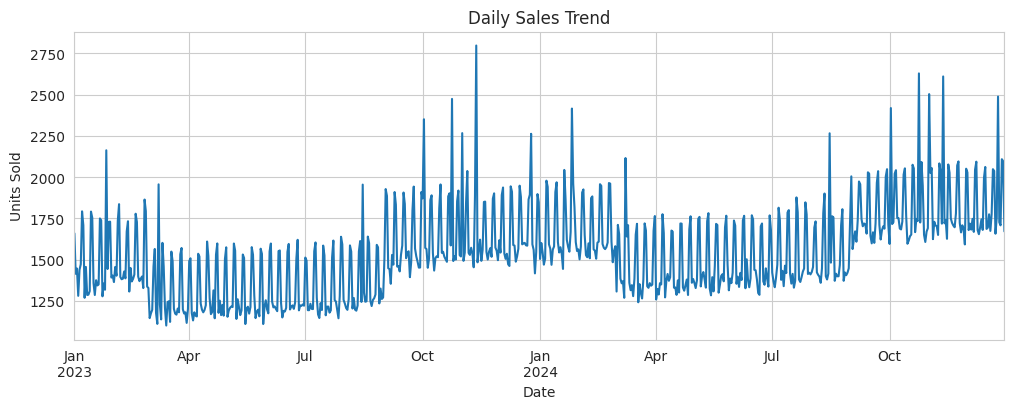

In [3]:
clean_df["Date"] = pd.to_datetime(clean_df["Date"])
daily = clean_df.groupby("Date")["Sales_Quantity"].sum()
plt.figure(figsize=(12,4))
daily.plot()
plt.title("Daily Sales Trend")
plt.ylabel("Units Sold")
plt.show()


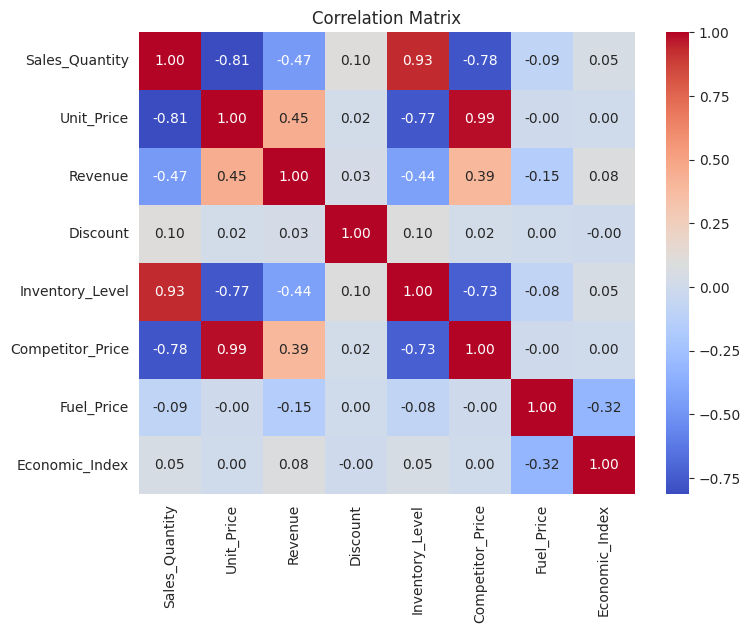

In [4]:
numeric_cols = ["Sales_Quantity","Unit_Price","Revenue","Discount","Inventory_Level",
                "Competitor_Price","Fuel_Price","Economic_Index"]
plt.figure(figsize=(8,6))
sns.heatmap(clean_df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()


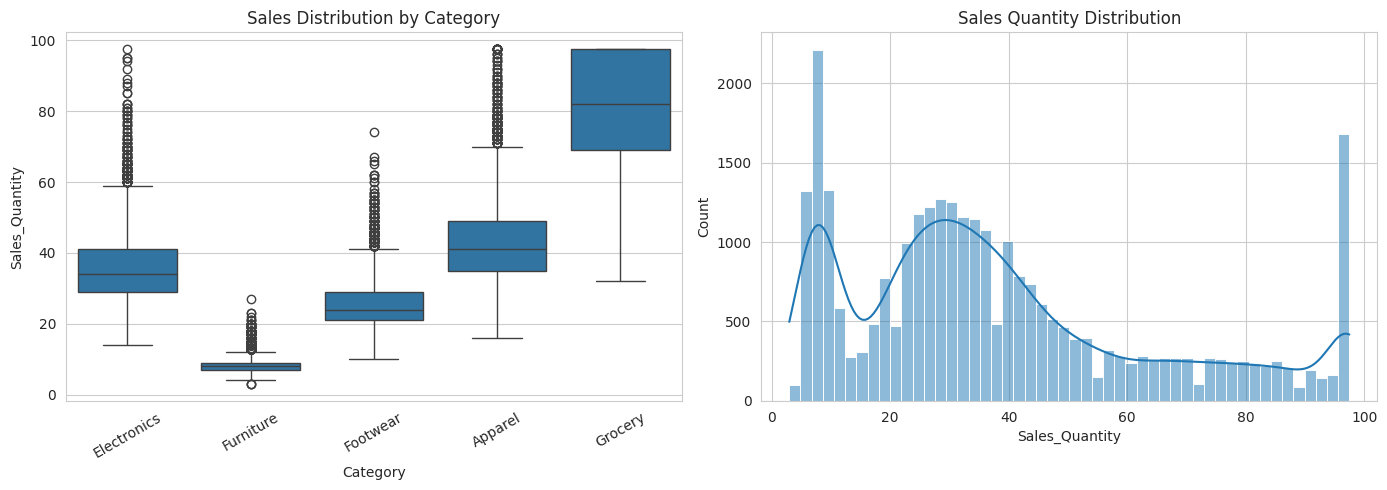

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.boxplot(data=clean_df, x="Category", y="Sales_Quantity", ax=axes[0])
axes[0].set_title("Sales Distribution by Category")
axes[0].tick_params(axis='x', rotation=30)

sns.histplot(clean_df["Sales_Quantity"], bins=50, kde=True, ax=axes[1])
axes[1].set_title("Sales Quantity Distribution")
plt.tight_layout()
plt.show()


## 3. Feature Engineering

In [6]:
feature_df, encoders = build_feature_pipeline(clean_df)
feature_df.to_csv("../data/retail_sales_features.csv", index=False)
print(feature_df.shape)
feature_df.head()


(29200, 49)


,Date,Product_ID,Product_Name,Category,Store_ID,Store_Location,Customer_ID,Sales_Quantity,Unit_Price,Revenue,...,Store_ID_enc,Store_Location_enc,Season_Autumn,Season_Spring,Season_Summer,Season_Winter,Weather_Cloudy,Weather_Cold,Weather_Rainy,Weather_Sunny
0,2023-01-01,P001,Wireless Mouse,Electronics,S01,Delhi,C1769,40.0,1117.44,44697.60,...,0,2,False,False,False,True,False,False,False,True
40,2023-01-02,P001,Wireless Mouse,Electronics,S01,Delhi,C5199,32.0,1295.31,41449.92,...,0,2,False,False,False,True,False,False,False,True
80,2023-01-03,P001,Wireless Mouse,Electronics,S01,Delhi,C9787,37.0,1266.34,46854.58,...,0,2,False,False,False,True,False,True,False,False
120,2023-01-04,P001,Wireless Mouse,Electronics,S01,Delhi,C8956,39.0,1247.16,38911.39,...,0,2,False,False,False,True,False,False,False,True
160,2023-01-05,P001,Wireless Mouse,Electronics,S01,Delhi,C7166,42.0,1215.72,44116.05,...,0,2,False,False,False,True,True,False,False,False


## 4. Model Training & Comparison

In [7]:
df = load_features("../data/retail_sales_features.csv")
results_df, best_name, best_model, feature_cols = train_and_compare(df)
results_df


LinearRegression     RMSE=   4.601  MAE=   3.331  R2=0.9731  MAPE=11.07%


DecisionTree         RMSE=   2.075  MAE=   1.215  R2=0.9945  MAPE=3.48%


RandomForest         RMSE=   1.518  MAE=   0.708  R2=0.9971  MAPE=2.28%


ExtraTrees           RMSE=   1.503  MAE=   0.951  R2=0.9971  MAPE=2.60%


GradientBoosting     RMSE=   0.984  MAE=   0.690  R2=0.9988  MAPE=2.06%


XGBoost              RMSE=   0.846  MAE=   0.451  R2=0.9991  MAPE=1.47%


LightGBM             RMSE=   0.786  MAE=   0.450  R2=0.9992  MAPE=1.52%

Best model: LightGBM  -> saved to models/best_model.pkl


,Model,MAE,RMSE,MSE,MAPE,R2,CV_RMSE,TrainTime_s
6,LightGBM,0.450,0.786,0.618,1.52,0.9992,1.736,0.78
5,XGBoost,0.451,0.846,0.716,1.47,0.9991,1.837,1.18
4,GradientBoosting,0.690,0.984,0.969,2.06,0.9988,1.100,18.12
3,ExtraTrees,0.951,1.503,2.258,2.60,0.9971,1.846,11.43
2,RandomForest,0.708,1.518,2.305,2.28,0.9971,1.355,32.82
1,DecisionTree,1.215,2.075,4.306,3.48,0.9945,2.622,0.30
0,LinearRegression,3.331,4.601,21.167,11.07,0.9731,4.971,0.12


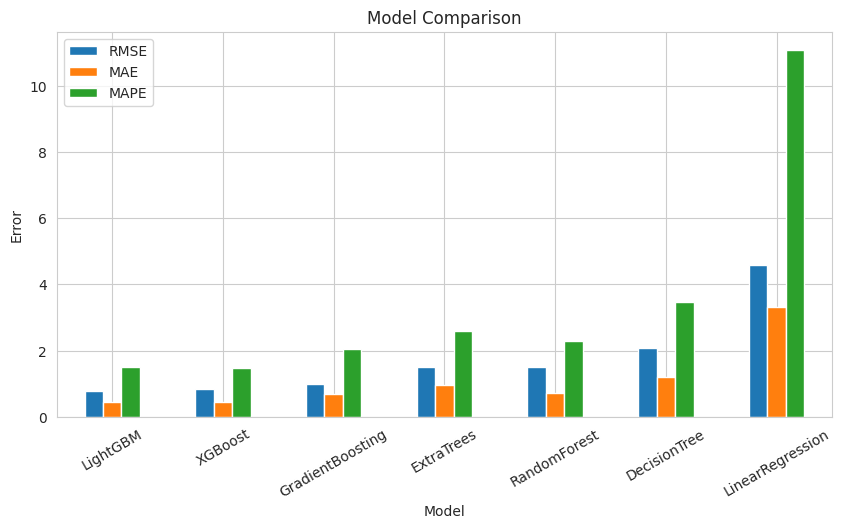

Best model: LightGBM


In [8]:
results_df.set_index("Model")[["RMSE","MAE","MAPE"]].plot(kind="bar", figsize=(10,5))
plt.title("Model Comparison")
plt.ylabel("Error")
plt.xticks(rotation=30)
plt.show()
print(f"Best model: {best_name}")


## 5. Forecasting

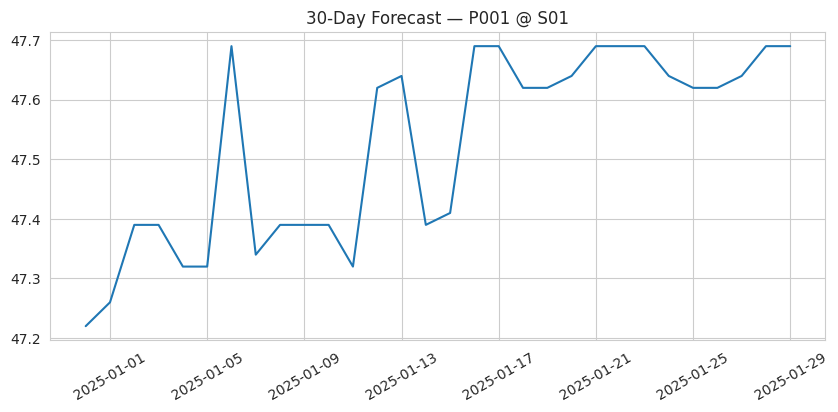

,Date,Product_ID,Store_ID,Predicted_Sales_Quantity
0,2024-12-31,P001,S01,47.22
1,2025-01-01,P001,S01,47.26
2,2025-01-02,P001,S01,47.39
3,2025-01-03,P001,S01,47.39
4,2025-01-04,P001,S01,47.32


In [9]:
model, feature_cols = load_artifacts()
fc = recursive_forecast(df, model, feature_cols, "P001", "S01", horizon_days=HORIZONS["30 Days"])
plt.figure(figsize=(10,4))
plt.plot(pd.to_datetime(fc["Date"]), fc["Predicted_Sales_Quantity"])
plt.title("30-Day Forecast — P001 @ S01")
plt.xticks(rotation=30)
plt.show()
fc.head()


## 6. Business Insights & Inventory Recommendations

In [10]:
insights = generate_business_insights(clean_df)
insights


{'best_selling': [{'Product_ID': 'P010',
   'Product_Name': 'Instant Noodles',
   'Sales_Quantity': 235834.5},
  {'Product_ID': 'P009',
   'Product_Name': 'Green Tea',
   'Sales_Quantity': 235737.0},
  {'Product_ID': 'P007',
   'Product_Name': 'Cotton T-Shirt',
   'Sales_Quantity': 125107.0},
  {'Product_ID': 'P008',
   'Product_Name': 'Denim Jeans',
   'Sales_Quantity': 125028.0},
  {'Product_ID': 'P001',
   'Product_Name': 'Wireless Mouse',
   'Sales_Quantity': 104207.0}],
 'worst_selling': [{'Product_ID': 'P004',
   'Product_Name': 'Study Desk',
   'Sales_Quantity': 23903.0},
  {'Product_ID': 'P003',
   'Product_Name': 'Office Chair',
   'Sales_Quantity': 24112.0},
  {'Product_ID': 'P006',
   'Product_Name': 'Formal Shoes',
   'Sales_Quantity': 74772.0},
  {'Product_ID': 'P005',
   'Product_Name': 'Running Shoes',
   'Sales_Quantity': 74777.0},
  {'Product_ID': 'P002',
   'Product_Name': 'Bluetooth Speaker',
   'Sales_Quantity': 103878.5}],
 'top_category': 'Grocery',
 'low_performi

In [11]:
recs = compute_recommendations(clean_df, fc)
recs


,Product_ID,Store_ID,Current_Inventory,Avg_Daily_Demand,Forecast_Demand_Horizon,Safety_Stock,Reorder_Point,Recommended_Restock_Qty,Alert
0,P001,S01,112.0,35.63,1425.7,43.2,292.6,1356.9,STOCKOUT RISK
